In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Libraries imported successfully.")
print("pandas version:", pd.__version__)

Libraries imported successfully.
pandas version: 2.2.3


In [ ]:
from google.colab import files
uploaded = files.upload()
fname = list(uploaded.keys())[0]
print("Uploaded file:", fname)

Saving train.csv to train.csv
Uploaded file: train.csv


In [ ]:
df = pd.read_csv(fname)
print("Rows, Columns :", df.shape)
df.head()

Rows, Columns : (103904, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [ ]:
display(df.describe().T)
display(df.describe(exclude='number').T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,103904.0,51951.500000,29994.645522,0.0,25975.75,51951.5,77927.25,103903.0
id,103904.0,64924.210502,37463.812252,1.0,32533.75,64856.5,97368.25,129880.0
Age,103904.0,39.379706,15.114964,7.0,27.00,40.0,51.00,85.0
Flight Distance,103904.0,1189.448375,997.147281,31.0,414.00,843.0,1743.00,4983.0
Inflight wifi service,103904.0,2.729683,1.327829,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,103904.0,3.060296,1.525075,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,103904.0,2.756901,1.398929,0.0,2.00,3.0,4.00,5.0
Gate location,103904.0,2.976883,1.277621,0.0,2.00,3.0,4.00,5.0
Food and drink,103904.0,3.202129,1.329533,0.0,2.00,3.0,4.00,5.0
Online boarding,103904.0,3.250375,1.349509,0.0,2.00,3.0,4.00,5.0


,count,unique,top,freq
Gender,103904,2,Female,52727
Customer Type,103904,2,Loyal Customer,84923
Type of Travel,103904,2,Business travel,71655
Class,103904,3,Business,49665
satisfaction,103904,2,neutral or dissatisfied,58879


In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(3)
missing_table = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print("Columns that contain missing values:")
display(missing_table[missing_table['Missing Count'] > 0])

with_missing = missing[missing > 0]
if len(with_missing) > 0:
    plt.figure(figsize=(7, 3.5))
    with_missing.plot(kind='bar', color='#1F4E79')
    plt.title('Missing Values per Column (before cleaning)')
    plt.ylabel('Number of missing values')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


Columns that contain missing values:


,Missing Count,Missing %


No missing values found.


In [ ]:
print("Duplicate rows found     :", df.duplicated().sum())
before = df.shape[0]
df = df.drop_duplicates()
print("Rows removed (duplicates):", before - df.shape[0])

# 'Unnamed: 0' is only a row index and 'id' is only an identifier.
# Neither carries information about satisfaction, so both are dropped.
df = df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')
print("Shape after cleaning     :", df.shape)
df.head()

Duplicate rows found     : 0
Rows removed (duplicates): 0
Shape after cleaning     : (103904, 23)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


In [ ]:
print("Missing values BEFORE:", int(df.isnull().sum().sum()))

num_cols = df.select_dtypes(include='number').columns
for col in num_cols:
    if df[col].isnull().any():
        median_value = df[col].median()
        df[col] = df[col].fillna(median_value)
        print(f"  '{col}' filled with median = {median_value}")

cat_cols = df.select_dtypes(exclude='number').columns
for col in cat_cols:
    if df[col].isnull().any():
        mode_value = df[col].mode()[0]
        df[col] = df[col].fillna(mode_value)
        print(f"  '{col}' filled with mode = {mode_value}")

print("Missing values AFTER :", int(df.isnull().sum().sum()))

Missing values BEFORE: 0
Missing values AFTER : 0


,Column,Q1,Q3,Lower Bound,Upper Bound,Outliers
0,Flight Distance,414.0,1743.0,-1579.5,3736.5,0
1,Departure Delay in Minutes,0.0,12.0,-18.0,30.0,0
2,Arrival Delay in Minutes,0.0,13.0,-19.5,32.5,0


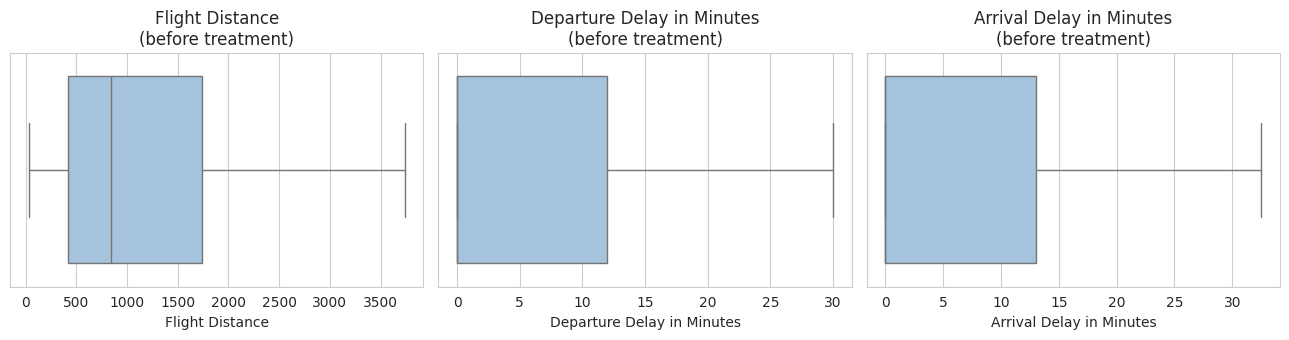

In [ ]:
outlier_cols = ['Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

bounds = {}
rows = []
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    bounds[col] = (low, high)
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append([col, round(Q1, 2), round(Q3, 2), round(low, 2), round(high, 2), n_out])

outlier_table = pd.DataFrame(rows, columns=['Column', 'Q1', 'Q3', 'Lower Bound', 'Upper Bound', 'Outliers'])
display(outlier_table)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color='#9DC3E6')
    ax.set_title(col + '\n(before treatment)')
plt.tight_layout()
plt.show()


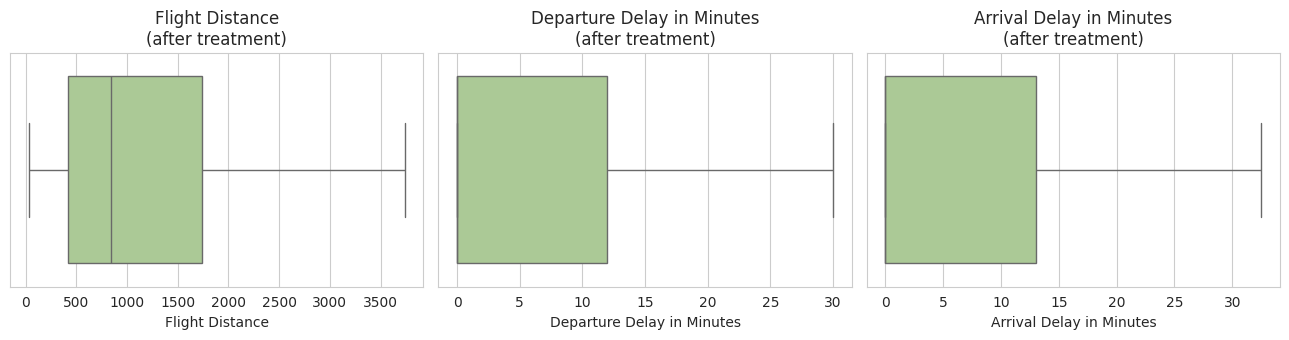

Rows kept: 103904


In [ ]:
for col in outlier_cols:
    low, high = bounds[col]
    df[col] = df[col].clip(lower=low, upper=high)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color='#A9D18E')
    ax.set_title(col + '\n(after treatment)')
plt.tight_layout()
plt.show()
print("Rows kept:", df.shape[0])

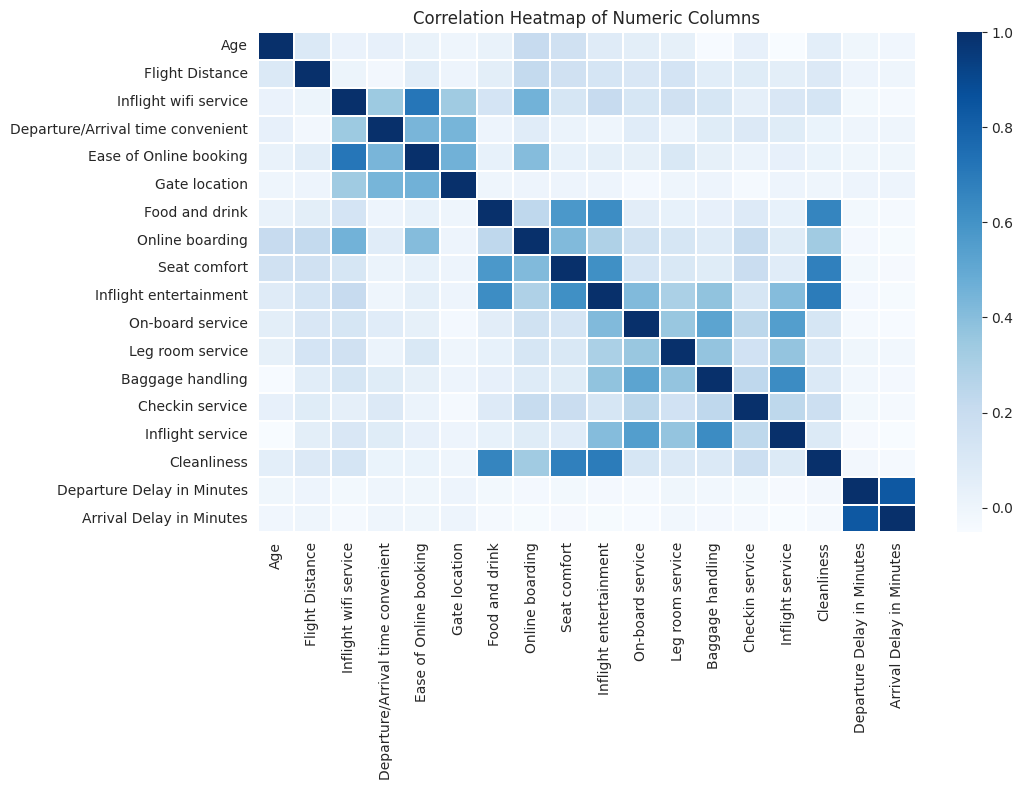

Highly correlated columns dropped (|correlation| > 0.9): []
Shape after data reduction: (103904, 23)


In [ ]:
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap='Blues', annot=False, linewidths=0.3)
plt.title('Correlation Heatmap of Numeric Columns')
plt.tight_layout()
plt.show()

# Find pairs whose correlation is above 0.9 and drop the second column of
# each pair (Arrival Delay is almost the same as Departure Delay, so one is enough)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c].abs() > 0.9).any()]
print("Highly correlated columns dropped (|correlation| > 0.9):", to_drop)
df = df.drop(columns=to_drop)
print("Shape after data reduction:", df.shape)

In [ ]:
df['satisfaction'] = df['satisfaction'].map({'neutral or dissatisfied': 0, 'satisfied': 1})

# 2) Class has a natural order, so use ordinal encoding
df['Class'] = df['Class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})

# 3) Other text columns have no order, so use one-hot encoding
df = pd.get_dummies(df, columns=['Gender', 'Customer Type', 'Type of Travel'],
                    drop_first=True, dtype=int)

print("Remaining text columns:", list(df.select_dtypes(exclude='number').columns))
print("Shape after encoding  :", df.shape)
display(df.head())
display(df.dtypes.value_counts())

Remaining text columns: []
Shape after encoding  : (103904, 23)


,Age,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel
0,13,1,460.0,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,0,1,0,1
1,25,2,235.0,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,0,1,1,0
2,26,2,1142.0,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,1,0,0,0
3,25,2,562.0,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,0,0,0,0
4,61,2,214.0,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,1,1,0,0


,count
int64,21
float64,2


In [ ]:
X = df.drop(columns=['satisfaction'])
y = df['satisfaction']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set:", X_train.shape, "  Test set:", X_test.shape)

show_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes']
print("\nBEFORE scaling (training set):")
display(X_train[show_cols].describe().loc[['min', 'max', 'mean']].round(2))

# The scaler learns min and max from the TRAINING data only,
# so no information from the test set leaks into the model.
scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("AFTER scaling (training set):")
display(X_train_scaled[show_cols].describe().loc[['min', 'max', 'mean']].round(3))

Training set: (83123, 22)   Test set: (20781, 22)

BEFORE scaling (training set):


,Age,Flight Distance,Departure Delay in Minutes
min,7.00,31.00,0.0
max,85.00,3736.50,30.0
mean,39.39,1183.46,7.4


AFTER scaling (training set):


,Age,Flight Distance,Departure Delay in Minutes
min,0.000,0.000,0.000
max,1.000,1.000,1.000
mean,0.415,0.311,0.247


In [ ]:
print("Missing values in training data :", int(X_train_scaled.isnull().sum().sum()))
print("Text columns left               :", len(X_train_scaled.select_dtypes(exclude='number').columns))
print("Final training features shape   :", X_train_scaled.shape)
print("Class balance in training labels:")
print(y_train.value_counts(normalize=True).round(3))

cleaned = pd.concat([X_train_scaled, y_train], axis=1)
cleaned.to_csv('Cleaned_Airline_Passenger_Data.csv', index=False)
print("\nSaved: Cleaned_Airline_Passenger_Data.csv")
display(cleaned.head())

from google.colab import files
files.download('Cleaned_Airline_Passenger_Data.csv')

Missing values in training data : 0
Text columns left               : 0
Final training features shape   : (83123, 22)
Class balance in training labels:
satisfaction
0    0.567
1    0.433
Name: proportion, dtype: float64

Saved: Cleaned_Airline_Passenger_Data.csv


,Age,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,satisfaction
30633,0.512821,1.0,0.402105,0.6,0.6,0.6,0.6,1.0,0.8,1.00,0.8,0.8,0.8,0.75,0.75,0.8,0.6,0.0,0.0,0.0,0.0,0.0,1
98857,0.358974,1.0,0.689516,0.6,0.6,0.6,0.8,0.6,0.6,1.00,0.6,1.0,1.0,1.00,1.00,0.8,0.6,0.0,0.0,1.0,1.0,0.0,0
80498,0.756410,0.0,0.140062,0.4,0.8,0.4,0.4,1.0,0.8,1.00,0.8,0.8,0.4,0.75,0.50,0.8,1.0,1.0,1.0,0.0,0.0,1.0,0
73981,0.243590,0.0,0.334098,1.0,0.8,0.8,0.2,0.6,1.0,0.50,0.6,1.0,0.2,1.00,0.50,0.8,0.6,0.0,0.0,1.0,1.0,0.0,1
70633,0.525641,0.0,0.190797,0.2,1.0,0.0,0.4,0.8,0.0,0.75,0.8,1.0,0.4,0.75,0.50,1.0,0.8,1.0,1.0,1.0,0.0,1.0,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>